# EC / IB / SP Density Distribution

Visualize density distributions of EC, IB, SP metrics from window-level background comparison.

**Input**: `results/window_compare/HiC_window_background.tsv`
**Output**: Three side-by-side histograms (EC, IB, SP)

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Configuration
WORKDIR = "/share/home/xhhuang24/project/PanTE/background_pool"
DATA_FILE = os.path.join(WORKDIR, "results", "window_compare", "HiC_window_background.tsv")
OUTDIR = os.path.join(WORKDIR, "..", "SNAP-HiC-Diff", "jupyter")

os.chdir(WORKDIR)
print(f"Working directory: {WORKDIR}")
print(f"Data file: {DATA_FILE}")
print(f"Output directory: {OUTDIR}")

Working directory: /share/home/xhhuang24/project/PanTE/background_pool
Data file: /share/home/xhhuang24/project/PanTE/background_pool/results/window_compare/HiC_window_background.tsv
Output directory: /share/home/xhhuang24/project/PanTE/background_pool/../SNAP-HiC-Diff/jupyter


In [2]:
# Load data
df = pd.read_csv(DATA_FILE, sep='\t')
print(f"Loaded {len(df)} rows, {df.shape[1]} columns")
print(f"\nColumns: {list(df.columns)}")
print(f"\nEC / IB / SP statistics:")
print(df[['EC', 'IB', 'SP']].describe())

Loaded 2152387 rows, 19 columns

Columns: ['chrom', 'window_id', 'window_start', 'window_end', 'EC', 'IB', 'SP', 'raw_sum_cpm_a', 'raw_sum_cpm_b', 'nz_frac_a', 'nz_frac_b', 'MSE', 'SSIM', 'Spearman', 'tw_statistic', 'tw_pvalue', 'comparison', 'sample_a', 'sample_b']

EC / IB / SP statistics:
                 EC            IB            SP
count  2.152387e+06  2.152387e+06  2.152387e+06
mean   4.579536e-03  1.302651e-01  8.289773e-01
std    1.143109e-03  1.074604e-01  7.168426e-02
min    2.267754e-03  8.609332e-10  4.392817e-01
25%    3.687195e-03  3.780951e-02  7.823029e-01
50%    4.448908e-03  1.039289e-01  8.345057e-01
75%    5.298444e-03  2.029971e-01  8.818956e-01
max    2.233613e-02  7.025163e-01  9.985191e-01


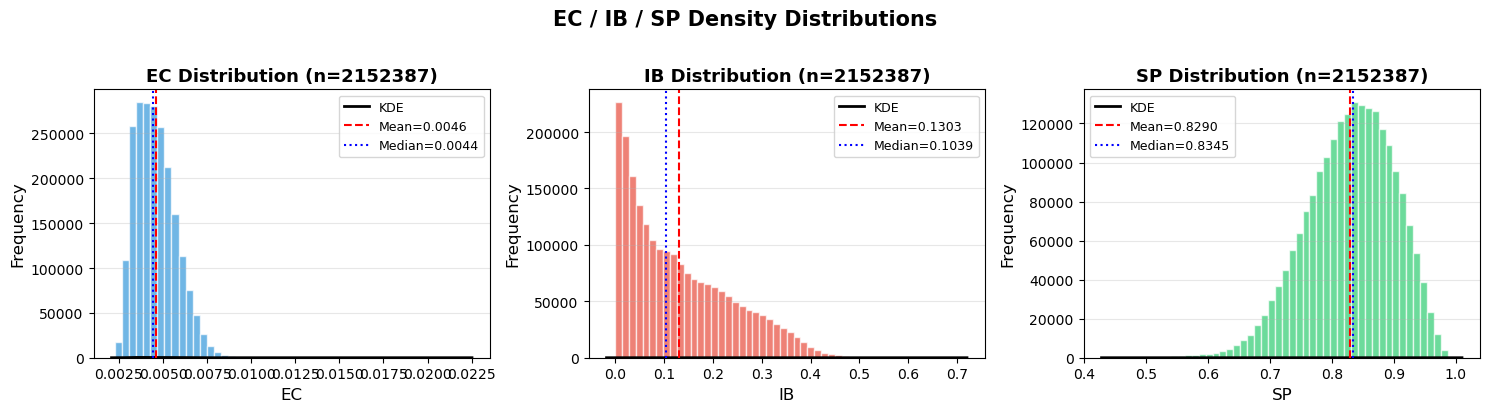


Figure saved to: /share/home/xhhuang24/project/PanTE/background_pool/../SNAP-HiC-Diff/jupyter/ec_ib_sp_distribution.png


In [3]:
# Plot histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

metrics = ['EC', 'IB', 'SP']
colors = ['#3498db', '#e74c3c', '#2ecc71']

for ax, metric, color in zip(axes, metrics, colors):
    data = df[metric].dropna()
    ax.hist(data, bins=50, color=color, alpha=0.7, edgecolor='white')
    
    # Add KDE overlay
    if len(data) > 1:
        try:
            sns.kdeplot(data, ax=ax, color='black', linewidth=2, label='KDE')
        except:
            pass
    
    ax.set_xlabel(metric, fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.set_title(f'{metric} Distribution (n={len(data)})', fontsize=13, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    
    # Add stats annotation
    mean_val = data.mean()
    median_val = data.median()
    ax.axvline(mean_val, color='red', linestyle='--', linewidth=1.5, label=f'Mean={mean_val:.4f}')
    ax.axvline(median_val, color='blue', linestyle=':', linewidth=1.5, label=f'Median={median_val:.4f}')
    ax.legend(fontsize=9)

plt.suptitle('EC / IB / SP Density Distributions', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(OUTDIR, 'ec_ib_sp_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print(f"\nFigure saved to: {os.path.join(OUTDIR, 'ec_ib_sp_distribution.png')}")

In [ ]:
# Summary table
summary = pd.DataFrame({
    'Metric': ['EC', 'IB', 'SP'],
    'Count': [df['EC'].count(), df['IB'].count(), df['SP'].count()],
    'Mean': [df['EC'].mean(), df['IB'].mean(), df['SP'].mean()],
    'Std': [df['EC'].std(), df['IB'].std(), df['SP'].std()],
    'Min': [df['EC'].min(), df['IB'].min(), df['SP'].min()],
    '25%': [df['EC'].quantile(0.25), df['IB'].quantile(0.25), df['SP'].quantile(0.25)],
    '50%': [df['EC'].median(), df['IB'].median(), df['SP'].median()],
    '75%': [df['EC'].quantile(0.75), df['IB'].quantile(0.75), df['SP'].quantile(0.75)],
    'Max': [df['EC'].max(), df['IB'].max(), df['SP'].max()]
})
print(summary.to_string(index=False))

Metric   Count     Mean      Std          Min      25%      50%      75%      Max
    EC 2152387 0.004580 0.001143 2.267754e-03 0.003687 0.004449 0.005298 0.022336
    IB 2152387 0.130265 0.107460 8.609332e-10 0.037810 0.103929 0.202997 0.702516
    SP 2152387 0.828977 0.071684 4.392817e-01 0.782303 0.834506 0.881896 0.998519


: 